<a href="https://colab.research.google.com/github/lucas-estanislau/pe-de-meia/blob/Analise-Explorat%C3%B3ria/03_analise_graficos_atualizados.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import drive
import pandas as pd
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


##**Comparação das taxas de abandono entre 2022 e 2025**

In [37]:
caminho = '/content/drive/MyDrive/pe-de-meia/inep/inep-data/taxas_em_uf_2007_2025.csv'

df_inep = pd.read_csv(caminho)
df_inep

,ANO,UF,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,2007,AC,74.4,9.5,16.1
1,2007,AL,69.0,8.5,22.5
2,2007,AM,77.4,11.0,11.6
3,2007,AP,68.2,10.9,20.9
4,2007,BA,67.6,11.6,20.8
...,...,...,...,...,...
508,2025,RS,91.3,6.1,2.6
509,2025,SC,88.8,7.3,3.9
510,2025,SE,94.0,4.2,1.8
511,2025,SP,93.7,2.8,3.5


In [38]:
anos = [2022, 2023, 2024, 2025]

df_comparacao = df_inep[
    df_inep["ANO"].isin(anos)
].copy()

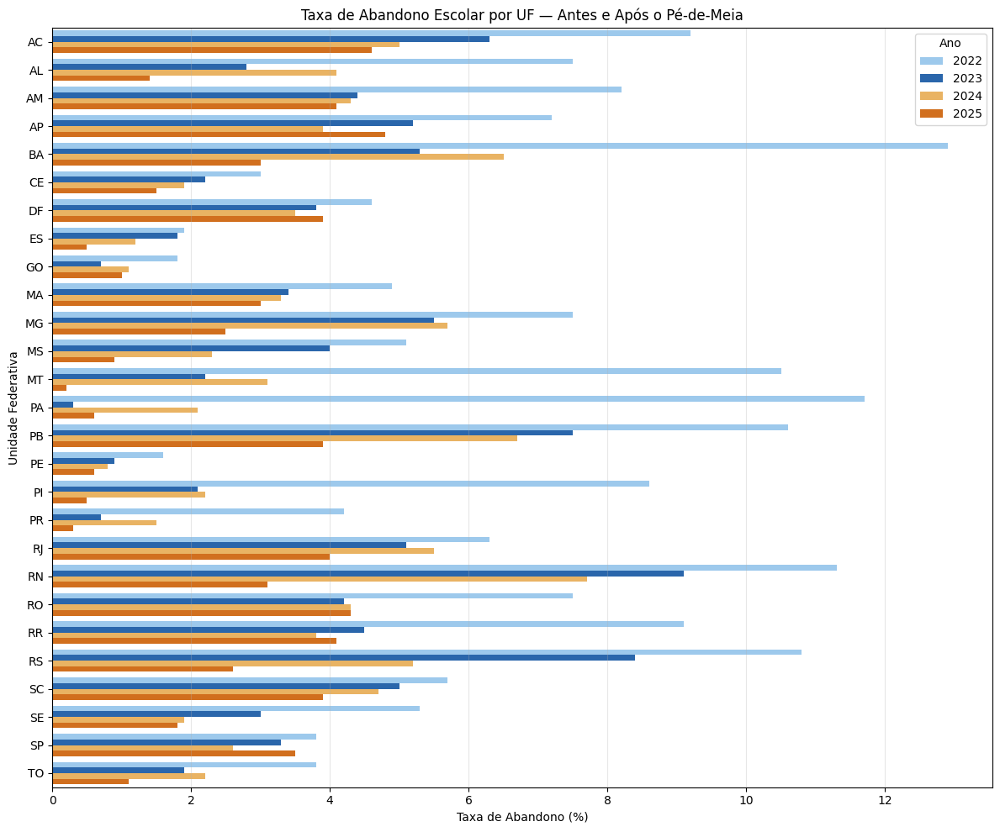

In [39]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ordenar os estados pela média da taxa de abandono
ordem_ufs = sorted(df_comparacao["UF"].unique())

plt.figure(figsize=(12, 10))

sns.barplot(
    data=df_comparacao,
    x="TAXA_ABANDONO",
    y="UF",
    hue="ANO",
    hue_order=[2022, 2023, 2024, 2025],
    order=ordem_ufs,
    dodge=True,
    palette={
        2022: "#90CAF9",
        2023: "#1565C0",
        2024: "#FFB74D",
        2025: "#EF6C00"
    },
    errorbar=None
)

plt.title("Taxa de Abandono Escolar por UF — Antes e Após o Pé-de-Meia")
plt.xlabel("Taxa de Abandono (%)")
plt.ylabel("Unidade Federativa")
plt.legend(title="Ano")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### A comparação por UF permite identificar que o abandono escolar não se distribui de maneira uniforme pelo país. As diferenças entre 2022 e 2023 mostram o cenário anterior ao Pé-de-Meia, enquanto 2024 e 2025 permitem acompanhar o período de implementação do programa. É importante observar cada estado individualmente, pois uma mudança nacional não significa que todas as UFs tiveram a mesma evolução.

### O gráfico apresenta a comparação das taxas de abandono escolar das unidades federativas entre 2022 e 2025. A visualização permite observar as diferenças entre os estados e acompanhar a evolução do indicador nos anos anteriores e posteriores ao início do Pé-de-Meia.

In [40]:
df_periodos = df_comparacao.copy()

df_periodos["PERIODO"] = df_periodos["ANO"].apply(
    lambda ano: "Antes" if ano <= 2023 else "Depois"
)

df_medias = (
    df_periodos
    .groupby(["UF", "PERIODO"])["TAXA_ABANDONO"]
    .mean()
    .unstack()
    .reset_index()
)

df_medias["DIFERENCA"] = (
    df_medias["Depois"] - df_medias["Antes"]
)

df_medias = df_medias.sort_values("DIFERENCA")

df_medias = df_medias.rename_axis(columns=None)
df_medias = df_medias.reset_index(drop=True)

display(df_medias)

,UF,Antes,Depois,DIFERENCA
0,RS,9.60,3.90,-5.70
1,RN,10.20,5.40,-4.80
2,MT,6.35,1.65,-4.70
3,PA,6.00,1.35,-4.65
4,BA,9.10,4.75,-4.35
5,PI,5.35,1.35,-4.00
6,PB,9.05,5.30,-3.75
7,MS,4.55,1.60,-2.95
8,AC,7.75,4.80,-2.95
9,RR,6.80,3.95,-2.85


### A tabela apresenta a média da taxa de abandono escolar por unidade federativa nos períodos anterior (2022–2023) e posterior (2024–2025) ao início do Pé-de-Meia. A coluna de diferença permite identificar se houve aumento ou redução do indicador em cada estado. Valores negativos representam redução da taxa de abandono, enquanto valores positivos indicam aumento.

##**O que mudou especificamente de 2024 para 2025?**

In [41]:
caminho = "/content/drive/MyDrive/pe-de-meia/agregados/pdm-tx-rendimento-2024-2025.csv"

df_final = pd.read_csv(caminho)

df_final

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,2024,AC,3.844802e+07,191904,86.8,8.2,5.0
1,2024,AL,1.462447e+08,729120,90.2,5.7,4.1
2,2024,AM,1.555299e+08,776280,89.2,6.5,4.3
3,2024,AP,3.629368e+07,181301,88.0,8.1,3.9
4,2024,BA,6.058837e+08,3018872,88.4,5.1,6.5
5,2024,CE,4.160727e+08,2078405,96.9,1.2,1.9
6,2024,DF,5.456692e+07,272775,86.4,10.1,3.5
7,2024,ES,7.818292e+07,390554,96.5,2.3,1.2
8,2024,GO,1.405325e+08,701655,96.9,2.0,1.1
9,2024,MA,3.647820e+08,1821065,92.1,4.6,3.3


In [42]:
df2024 = df_final.loc[df_final['ANO'] == 2024].reset_index()
df2024['TAXA_ABANDONO'].astype(float)
df2024

,index,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,0,2024,AC,38448025.0,191904,86.8,8.2,5.0
1,1,2024,AL,146244725.0,729120,90.2,5.7,4.1
2,2,2024,AM,155529925.0,776280,89.2,6.5,4.3
3,3,2024,AP,36293675.0,181301,88.0,8.1,3.9
4,4,2024,BA,605883725.0,3018872,88.4,5.1,6.5
5,5,2024,CE,416072725.0,2078405,96.9,1.2,1.9
6,6,2024,DF,54566925.0,272775,86.4,10.1,3.5
7,7,2024,ES,78182925.0,390554,96.5,2.3,1.2
8,8,2024,GO,140532500.0,701655,96.9,2.0,1.1
9,9,2024,MA,364782025.0,1821065,92.1,4.6,3.3


In [43]:
df2025 = df_final.loc[df_final['ANO'] == 2025].reset_index()
df2025['TAXA_ABANDONO'].astype(float)
df2025

,index,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,27,2025,AC,7.535052e+07,286595,89.2,6.2,4.6
1,28,2025,AL,2.739513e+08,1022348,95.9,2.7,1.4
2,29,2025,AM,4.194634e+08,1609164,89.4,6.5,4.1
3,30,2025,AP,7.053230e+07,273647,90.1,5.1,4.8
4,31,2025,BA,1.105413e+09,4154600,92.4,4.6,3.0
5,32,2025,CE,7.770466e+08,2817457,97.5,1.0,1.5
6,33,2025,DF,1.068086e+08,399980,82.4,13.7,3.9
7,34,2025,ES,1.628706e+08,601123,98.4,1.1,0.5
8,35,2025,GO,3.159621e+08,1167785,97.8,1.2,1.0
9,36,2025,MA,6.525316e+08,2451427,93.2,3.8,3.0


In [44]:
dfmedia = pd.DataFrame()
dfmedia['ABANDONO_2024'] = df2024['TAXA_ABANDONO']
dfmedia['ABANDONO_2025'] = df2025['TAXA_ABANDONO']
dfmedia['DIFERENCA_ABANDONO'] = df2025['TAXA_ABANDONO'] - df2024['TAXA_ABANDONO']
dfmedia

,ABANDONO_2024,ABANDONO_2025,DIFERENCA_ABANDONO
0,5.0,4.6,-0.4
1,4.1,1.4,-2.7
2,4.3,4.1,-0.2
3,3.9,4.8,0.9
4,6.5,3.0,-3.5
5,1.9,1.5,-0.4
6,3.5,3.9,0.4
7,1.2,0.5,-0.7
8,1.1,1.0,-0.1
9,3.3,3.0,-0.3


In [45]:
dfmedia['DIFERENCA_ABANDONO'].mean()

np.float64(-1.162962962962963)

In [46]:
# Quantas UFs reduziram a taxa de abandono?
reduziram = (dfmedia["DIFERENCA_ABANDONO"] < 0).sum()

# Quantas aumentaram?
aumentaram = (dfmedia["DIFERENCA_ABANDONO"] > 0).sum()

# Quantas permaneceram iguais?
iguais = (dfmedia["DIFERENCA_ABANDONO"] == 0).sum()

print("UFs que reduziram:", reduziram)
print("UFs que aumentaram:", aumentaram)
print("UFs sem alteração:", iguais)

UFs que reduziram: 22
UFs que aumentaram: 4
UFs sem alteração: 1


##**Mapas de abandono e pagamentos do Pé-de-Meia**

In [47]:
!pip install geobr

In [48]:
!pip install "duckdb<2"

In [49]:
import plotly.graph_objects as go
import geobr
import json

# Selecionar os dados de 2024 e 2025
df_mapa = df_final[
    df_final["ANO"].isin([2024, 2025])
].groupby(
    ["UF", "ANO"],
    as_index=False
)["TAXA_ABANDONO"].mean()

# Carregar o mapa dos estados
estados = geobr.read_state(year=2020, output="gpd")
geojson = json.loads(estados.to_json())

# Definir os limites da escala para os dois anos
menor_taxa = df_mapa["TAXA_ABANDONO"].min()
maior_taxa = df_mapa["TAXA_ABANDONO"].max()

# Separar os dados por ano
df_2024 = df_mapa[df_mapa["ANO"] == 2024]
df_2025 = df_mapa[df_mapa["ANO"] == 2025]

# Criar o mapa
fig = go.Figure()

# Mapa de 2024 - azul
fig.add_trace(go.Choropleth(
    geojson=geojson,
    locations=df_2024["UF"],
    z=df_2024["TAXA_ABANDONO"],
    featureidkey="properties.abbrev_state",
    colorscale=[
        [0, "#BBDEFB"],
        [1, "#1565C0"]
    ],
    zmin=menor_taxa,
    zmax=maior_taxa,
    colorbar=dict(title="Taxa de abandono (%)"),
    customdata=df_2024["TAXA_ABANDONO"],
    hovertemplate=(
        "<b>%{location}</b><br>"
        "Taxa de abandono: %{customdata:.2f}%"
        "<extra>2024</extra>"
    ),
    visible=True
))

# Mapa de 2025 - laranja
fig.add_trace(go.Choropleth(
    geojson=geojson,
    locations=df_2025["UF"],
    z=df_2025["TAXA_ABANDONO"],
    featureidkey="properties.abbrev_state",
    colorscale=[
        [0, "#FFE0B2"],
        [1, "#FF9800"]
    ],
    zmin=menor_taxa,
    zmax=maior_taxa,
    colorbar=dict(title="Taxa de abandono (%)"),
    customdata=df_2025["TAXA_ABANDONO"],
    hovertemplate=(
        "<b>%{location}</b><br>"
        "Taxa de abandono: %{customdata:.2f}%"
        "<extra>2025</extra>"
    ),
    visible=False
))

# Criar os botões para selecionar o ano
fig.update_layout(
    updatemenus=[dict(
        type="buttons",
        direction="right",
        x=0.5,
        y=-0.08,
        xanchor="center",
        yanchor="top",
        buttons=[
            dict(
                label="2024",
                method="update",
                args=[
                    {"visible": [True, False]},
                    {"title": "Taxa de Abandono Escolar por UF — 2024"}
                ]
            ),
            dict(
                label="2025",
                method="update",
                args=[
                    {"visible": [False, True]},
                    {"title": "Taxa de Abandono Escolar por UF — 2025"}
                ]
            )
        ]
    )],
    title="Taxa de Abandono Escolar por UF — 2024",
    title_x=0.5,
    width=1000,
    height=700,
    geo=dict(
        fitbounds="locations",
        visible=False,
        showframe=False,
        showcoastlines=False,
        bgcolor="white"
    ),
    margin=dict(l=10, r=10, t=100, b=100)
)

fig.show()


### O mapa permite localizar as UFs com maiores e menores taxas de abandono em cada ano. A escala de cores é mantida igual para 2024 e 2025, permitindo comparar os dois períodos sem distorcer visualmente as diferenças. A visualização mostra a distribuição territorial do indicador, mas, isoladamente, não permite atribuir eventuais reduções ao Pé-de-Meia.



##**Gráfico de pagamentos versus taxa de abandono**

In [50]:
import plotly.graph_objects as go
import geobr
import json

# Selecionar os dados de pagamentos de 2024 e 2025
df_mapa_pagamentos = df_final[
    df_final["ANO"].isin([2024, 2025])
].groupby(
    ["UF", "ANO"],
    as_index=False
)["VALOR_TOTAL"].sum()

# Carregar o mapa dos estados
estados = geobr.read_state(year=2020, output="gpd")
geojson = json.loads(estados.to_json())

# Definir os limites da escala para os dois anos
menor_valor = df_mapa_pagamentos["VALOR_TOTAL"].min()
maior_valor = df_mapa_pagamentos["VALOR_TOTAL"].max()

# Separar os dados por ano
df_pagamentos_2024 = df_mapa_pagamentos[
    df_mapa_pagamentos["ANO"] == 2024
]

df_pagamentos_2025 = df_mapa_pagamentos[
    df_mapa_pagamentos["ANO"] == 2025
]

# Criar o mapa
fig = go.Figure()

# Mapa de 2024 - azul
fig.add_trace(go.Choropleth(
    geojson=geojson,
    locations=df_pagamentos_2024["UF"],
    z=df_pagamentos_2024["VALOR_TOTAL"],
    featureidkey="properties.abbrev_state",
    colorscale=[
        [0, "#BBDEFB"],
        [1, "#1565C0"]
    ],
    zmin=menor_valor,
    zmax=maior_valor,
    colorbar=dict(title="Valor total pago (R$)"),
    customdata=df_pagamentos_2024["VALOR_TOTAL"],
    hovertemplate=(
        "<b>%{location}</b><br>"
        "Valor total pago: R$ %{customdata:,.2f}"
        "<extra>2024</extra>"
    ),
    visible=True
))

# Mapa de 2025 - laranja
fig.add_trace(go.Choropleth(
    geojson=geojson,
    locations=df_pagamentos_2025["UF"],
    z=df_pagamentos_2025["VALOR_TOTAL"],
    featureidkey="properties.abbrev_state",
    colorscale=[
        [0, "#FFE0B2"],
        [1, "#FF9800"]
    ],
    zmin=menor_valor,
    zmax=maior_valor,
    colorbar=dict(title="Valor total pago (R$)"),
    customdata=df_pagamentos_2025["VALOR_TOTAL"],
    hovertemplate=(
        "<b>%{location}</b><br>"
        "Valor total pago: R$ %{customdata:,.2f}"
        "<extra>2025</extra>"
    ),
    visible=False
))

# Criar os botões para selecionar o ano
fig.update_layout(
    updatemenus=[dict(
        type="buttons",
        direction="right",
        x=0.5,
        y=-0.08,
        xanchor="center",
        yanchor="top",
        buttons=[
            dict(
                label="2024",
                method="update",
                args=[
                    {"visible": [True, False]},
                    {"title": "Pagamentos do Pé-de-Meia por UF — 2024"}
                ]
            ),
            dict(
                label="2025",
                method="update",
                args=[
                    {"visible": [False, True]},
                    {"title": "Pagamentos do Pé-de-Meia por UF — 2025"}
                ]
            )
        ]
    )],
    title="Pagamentos do Pé-de-Meia por UF — 2024",
    title_x=0.5,
    width=1100,
    height=700,
    geo=dict(
        fitbounds="locations",
        visible=False,
        showframe=False,
        showcoastlines=False,
        bgcolor="white"
    ),
    margin=dict(l=10, r=10, t=100, b=100)
)

fig.show()


In [51]:
import plotly.graph_objects as go

# Agrupar os dados por estado e ano
df_grafico = df_final[df_final["ANO"].isin([2024, 2025])].groupby(
    ["UF", "ANO"], as_index=False
).agg({
    "TAXA_ABANDONO": "mean",
    "VALOR_TOTAL": "sum"
})

fig = go.Figure()

# Dados de 2024
df_2024 = df_grafico[df_grafico["ANO"] == 2024]

fig.add_trace(go.Bar(
    x=df_2024["UF"],
    y=df_2024["TAXA_ABANDONO"],
    name="Abandono 2024",
    marker_color="#90CAF9",
    offsetgroup="2024",
    yaxis="y"
))

fig.add_trace(go.Scatter(
    x=df_2024["UF"],
    y=df_2024["VALOR_TOTAL"] / 1_000_000,
    name="Pagamentos 2024",
    mode="lines+markers",
    line=dict(color="#1565C0", width=2),
    marker=dict(size=5),
    yaxis="y2"
))

# Dados de 2025
df_2025 = df_grafico[df_grafico["ANO"] == 2025]

fig.add_trace(go.Bar(
    x=df_2025["UF"],
    y=df_2025["TAXA_ABANDONO"],
    name="Abandono 2025",
    marker_color="#FFE0B2",
    offsetgroup="2025",
    yaxis="y"
))

fig.add_trace(go.Scatter(
    x=df_2025["UF"],
    y=df_2025["VALOR_TOTAL"] / 1_000_000,
    name="Pagamentos 2025",
    mode="lines+markers",
    line=dict(color="#EF6C00", width=2),
    marker=dict(size=5),
    yaxis="y2"
))

fig.update_layout(
    title="Taxa de Abandono e Pagamentos do Pé-de-Meia por UF",
    title_x=0.5,

    barmode="group",

    xaxis=dict(
        title="Unidade Federativa",
        categoryorder="category ascending"
    ),

    yaxis=dict(
        title="Taxa de abandono (%)",
        showgrid=True,
        gridcolor="#EAEAEA",
        zeroline=False
    ),

    yaxis2=dict(
        title="Pagamentos (R$ milhões)",
        overlaying="y",
        side="right",
        showgrid=False,
        zeroline=False
    ),

    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="center",
        x=0.5
    ),

    template="plotly_white",
    width=1100,
    height=600,
    margin=dict(l=60, r=60, t=110, b=60),
    hovermode="x unified"
)

fig.show()

### O gráfico reúne, por UF, a taxa de abandono (barras) e o total de pagamentos (linhas), permitindo observar os dois indicadores lado a lado em 2024 e 2025. O volume de pagamentos varia bastante entre os estados, mas isso não significa, por si só, que os estados que receberam mais recursos tiveram maior ou menor redução do abandono. A comparação é exploratória e não demonstra uma relação de causa e efeito.

In [52]:
df_final.loc[(df_final['UF'] == 'SP') | (df_final['UF'] == 'BA')]

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
4,2024,BA,6.058837e+08,3018872,88.4,5.1,6.5
25,2024,SP,6.472612e+08,3235801,94.0,3.4,2.6
31,2025,BA,1.105413e+09,4154600,92.4,4.6,3.0
52,2025,SP,1.280234e+09,4520212,93.7,2.8,3.5


In [53]:
df_final.loc[df_final['VALOR_TOTAL'] > 1000000000]

,ANO,UF,VALOR_TOTAL,QUANTIDADE_PAGAMENTOS,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
31,2025,BA,1.105413e+09,4154600,92.4,4.6,3.0
52,2025,SP,1.280234e+09,4520212,93.7,2.8,3.5


##**A série histórica de 2007 a 2025**

In [54]:
caminho = '/content/drive/MyDrive/pe-de-meia/inep/inep-data/taxas_em_uf_2007_2025.csv'

In [55]:
df_inep = pd.read_csv(caminho)
df_inep.head()

,ANO,UF,TAXA_APROVACAO,TAXA_REPROVACAO,TAXA_ABANDONO
0,2007,AC,74.4,9.5,16.1
1,2007,AL,69.0,8.5,22.5
2,2007,AM,77.4,11.0,11.6
3,2007,AP,68.2,10.9,20.9
4,2007,BA,67.6,11.6,20.8


In [56]:
import plotly.express as px
import plotly.graph_objects as go

# Média simples das taxas das UFs em cada ano
df_media_brasil = (
    df_inep.groupby("ANO", as_index=False)["TAXA_ABANDONO"]
    .mean()
)

fig = px.line(
    df_inep.sort_values(["UF", "ANO"]),
    x="ANO",
    y="TAXA_ABANDONO",
    color="UF",
    markers=True,
    category_orders={
        "UF": sorted(df_inep["UF"].unique())
    },
    title="Evolução da Taxa de Abandono Escolar por UF (2007–2025)",
    labels={
        "ANO": "Ano",
        "TAXA_ABANDONO": "Taxa de Abandono (%)",
        "UF": "Estado"
    }
)

# Ocultar inicialmente as linhas dos estados
fig.update_traces(visible="legendonly")

# Período da pandemia e pós-pandemia
fig.add_vrect(
    x0=2019.5,
    x1=2023.5,
    fillcolor="lightcoral",
    opacity=0.20,
    layer="below",
    line_width=0,
    annotation_text="Pandemia e pós-pandemia",
    annotation_position="top left",
    annotation_font_size=12,
    annotation_font_color="darkred"
)

# Período do Pé-de-Meia
fig.add_vrect(
    x0=2023.5,
    x1=2025.5,
    fillcolor="lightgreen",
    opacity=0.25,
    layer="below",
    line_width=0,
    annotation_text="Pé-de-Meia",
    annotation_position="top left",
    annotation_font_size=12,
    annotation_font_color="darkgreen"
)

# Linha da média das UFs: sempre visível
fig.add_trace(
    go.Scatter(
        x=df_media_brasil["ANO"],
        y=df_media_brasil["TAXA_ABANDONO"],
        mode="lines+markers",
        name="Média das UFs",
        line=dict(
            color="black",
            width=3,
            dash="dash"
        ),
        marker=dict(size=6),
        hovertemplate=
            "Ano: %{x}<br>" +
            "Média das UFs: %{y:.2f}%<extra></extra>"
    )
)

fig.update_layout(
    width=1200,
    height=650,
    hovermode="x unified",
    legend_title="Selecione os estados",
    yaxis_title="Taxa de Abandono (%)"
)

fig.update_xaxes(dtick=1)

fig.show()


### A série histórica permite observar a evolução do abandono escolar ao longo de 2007 a 2025 e comparar o comportamento das UFs. Um ponto que merece atenção é a queda acentuada em 2020 e a retomada nos anos seguintes, período que coincide com a pandemia e mudanças no funcionamento e acompanhamento escolar. Por isso, a interpretação dos anos recentes deve considerar esse contexto, além do início do Pé-de-Meia em 2024.

In [57]:
import plotly.express as px
import plotly.graph_objects as go

# Média simples das taxas das UFs em cada ano
df_media_brasil_aprovacao = (
    df_inep.groupby("ANO", as_index=False)["TAXA_APROVACAO"]
    .mean()
)

fig = px.line(
    df_inep.sort_values(["UF", "ANO"]),
    x="ANO",
    y="TAXA_APROVACAO",
    color="UF",
    markers=True,
    title="Evolução da Taxa de Aprovação Escolar por UF (2007–2025)",
    labels={
        "ANO": "Ano",
        "TAXA_APROVACAO": "Taxa de aprovação (%)",
        "UF": "Estado"
    }
)

# Ocultar inicialmente as linhas dos estados
fig.update_traces(visible="legendonly")

# Sombreamento da pandemia e pós-pandemia
fig.add_vrect(
    x0=2019.5,
    x1=2023.5,
    fillcolor="red",
    opacity=0.10,
    line_width=0,
    annotation_text="Pandemia e pós-pandemia",
    annotation_position="top left"
)

# Sombreamento do Pé-de-Meia
fig.add_vrect(
    x0=2023.5,
    x1=2025.5,
    fillcolor="green",
    opacity=0.12,
    line_width=0,
    annotation_text="Pé-de-Meia",
    annotation_position="top left"
)

# Linha da média das UFs: sempre visível
fig.add_trace(
    go.Scatter(
        x=df_media_brasil_aprovacao["ANO"],
        y=df_media_brasil_aprovacao["TAXA_APROVACAO"],
        mode="lines+markers",
        name="Média das UFs",
        line=dict(
            color="black",
            width=3,
            dash="dash"
        ),
        marker=dict(size=6),
        hovertemplate=
            "Ano: %{x}<br>" +
            "Média das UFs: %{y:.2f}%<extra></extra>"
    )
)

fig.update_layout(
    width=1100,
    height=600,
    hovermode="x unified",
    xaxis=dict(
        tickmode="linear",
        tick0=2007,
        dtick=1,
        range=[2006.5, 2025.5]
    ),
    yaxis=dict(
        title="Taxa de aprovação (%)",
        range=[0, 100]
    ),
    legend=dict(
        title="Selecione os estados",
        x=1.02,
        y=1
    )
)

fig.show()


### A evolução da taxa de aprovação mostra como o indicador se comportou nas UFs ao longo da série histórica. O aumento observado em 2020, em conjunto com a queda do abandono no mesmo período, deve ser interpretado com cautela, pois pode refletir mudanças nas regras de avaliação e aprovação durante a pandemia. Como o Pé-de-Meia começou em 2024, a série ajuda a contextualizar tendências anteriores, mas ainda não permite concluir que o programa causou mudanças na aprovação.

In [58]:
print(df_final.columns.tolist())

['ANO', 'UF', 'VALOR_TOTAL', 'QUANTIDADE_PAGAMENTOS', 'TAXA_APROVACAO', 'TAXA_REPROVACAO', 'TAXA_ABANDONO']


Como é possível observar, a taxa de aprovação apresenta um pico de 2019 para 2020, o que pode possivelmente estar relacionado a regras menos rígidas para aprovação na maioria das UFs. Consequentemente, isso contribui para uma menor taxa de abandono.

## Contexto externo: pandemia (Lei 14.040/2020) e Novo Ensino Médio (Lei 14.945/2024)

Nesta seção a série do INEP (2007–2025) é lida junto com os marcos normativos do período. O objetivo é explicar os movimentos observados nos gráficos anteriores e deixar claro o que os dados **permitem** e **não permitem** concluir.

**Marcos usados (fontes externas conferidas):**

| Ano | Marco | O que mudou |
|---|---|---|
| 2017 | Lei 13.415/2017 | Primeira versão da reforma do Novo Ensino Médio |
| 2020 | Lei 14.040/2020 (18/08/2020) | Normas excepcionais na pandemia: dispensa dos 200 dias letivos, mantida a carga horária mínima (800 h), uso de atividades não presenciais e possibilidade de *continuum* curricular 2020–2021 |
| 2021 | Lei 14.218/2021 | As normas excepcionais passam a valer até o fim do ano letivo de 2021 |
| 2022 | Cronograma original do Novo EM | Implementação prevista a partir da 1ª série (a adesão variou entre as redes) |
| 2023 | Portaria MEC 627/2023 (04/04/2023) | Suspensão do cronograma nacional de implementação, para reavaliar a reforma |
| 2024 | Lei 14.945/2024 (31/07/2024) | Nova Política Nacional de Ensino Médio; formação geral básica ampliada para 3.000 h |
| 2024 | Pé-de-Meia | Início dos pagamentos (marco usado ao longo deste caderno) |
| 2025–2027 | Implementação da Lei 14.945/2024 | Escalonada: 1ª série em 2025, 2ª em 2026 e 3ª em 2027, com variação entre estados |

> Atenção: algumas redes estaduais adotaram cronogramas próprios, e há fontes que tratam 2026 como o ano em que todas as séries já estão no novo modelo. Para 2024–2025, portanto, o Novo EM atinge só parte dos estudantes e de forma desigual entre UFs.

In [59]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from plotly.subplots import make_subplots

caminho_inep = '/content/drive/MyDrive/pe-de-meia/inep/inep-data/taxas_em_uf_2007_2025.csv'
df_inep = pd.read_csv(caminho_inep)

# Indicadores disponíveis (a reprovação só entra se a coluna existir no arquivo)
candidatos = {
    "TAXA_APROVACAO": "Aprovação",
    "TAXA_REPROVACAO": "Reprovação",
    "TAXA_ABANDONO": "Abandono",
}
indicadores = {c: n for c, n in candidatos.items() if c in df_inep.columns}
print("Indicadores usados:", list(indicadores))

# Marcos para anotar nos gráficos: (ano, rótulo curto)
MARCOS = [
    (2020, "Lei 14.040/2020<br>(pandemia)"),
    (2022, "Início previsto<br>do Novo EM"),
    (2023, "Suspensão do<br>cronograma"),
    (2024, "Lei 14.945 +<br>Pé-de-Meia"),
]


def adicionar_marcos(fig, linhas, rotulo_linha=1):
    """Linhas verticais e rótulos alternados para evitar sobreposição."""

    alturas = [1.02, 1.13, 1.02, 1.13]

    for (ano, rotulo), altura in zip(MARCOS, alturas):
        fig.add_vline(
            x=ano,
            line_dash="dot",
            line_color="gray",
            line_width=1,
            row="all",
            col=1
        )

        fig.add_annotation(
            x=ano,
            y=altura,
            xref="x",
            yref="paper",
            yanchor="bottom",
            text=rotulo,
            showarrow=False,
            font=dict(size=9, color="dimgray"),
            align="center"
        )

    fig.update_layout(
        margin=dict(t=140)
    )

Indicadores usados: ['TAXA_APROVACAO', 'TAXA_REPROVACAO', 'TAXA_ABANDONO']


### 1. Visão geral: aprovação, reprovação e abandono juntos

Em vez de uma linha por UF (27 linhas sobrepostas), o gráfico abaixo mostra só a **média das UFs** de cada indicador, em painéis alinhados no mesmo eixo de tempo, com os marcos anotados. Assim fica fácil ver se os três indicadores se movem em conjunto nos mesmos anos.

A média é simples (cada UF tem o mesmo peso, independentemente do número de matrículas), então ela não equivale à taxa nacional.

In [60]:
media_ano = df_inep.groupby("ANO")[list(indicadores)].mean()

n = len(indicadores)
fig = make_subplots(rows=n, cols=1, shared_xaxes=True, vertical_spacing=0.06,
                    subplot_titles=[f"{nome} (%)" for nome in indicadores.values()])

cores = {"Aprovação": "#2E7D32", "Reprovação": "#F9A825", "Abandono": "#C62828"}
for i, (col, nome) in enumerate(indicadores.items(), start=1):
    fig.add_trace(go.Scatter(
        x=media_ano.index, y=media_ano[col], mode="lines+markers", name=nome,
        line=dict(color=cores[nome], width=3),
        hovertemplate="Ano: %{x}<br>" + nome + ": %{y:.2f}%<extra></extra>"
    ), row=i, col=1)

adicionar_marcos(fig, n)
fig.update_layout(height=260 * n + 120, width=1100, template="plotly_white",
                  showlegend=False, hovermode="x unified",
                  title=dict(text="Média das UFs — Ensino Médio, 2007–2025", x=0.5),
                  margin=dict(t=120))
fig.update_xaxes(dtick=1)
fig.show()

O gráfico mostra que, em 2020, durante a pandemia, houve um aumento significativo da aprovação e uma queda na reprovação e no abandono, possivelmente influenciados pelas medidas de flexibilização escolar. Após esse período, com o retorno das aulas presenciais, os indicadores voltaram a oscilar. A partir de 2022, período de implementação do Novo Ensino Médio, observa-se uma recuperação gradual. Já em 2024, com a chegada do programa Pé-de-Meia, a aprovação continuou crescendo e o abandono diminuiu, indicando uma possível melhora na permanência dos estudantes na escola.

### 2. Pandemia: quanto o indicador se afastou do padrão anterior?

Para medir o efeito da pandemia sem depender só do olhar, comparamos cada período com a **linha de base pré-pandemia (2017–2019)**. A diferença é dada em pontos percentuais (p.p.).

In [61]:
def periodo(ano):
    if ano <= 2016: return None
    if ano <= 2019: return "1. Pré-pandemia (2017–2019)"
    if ano <= 2021: return "2. Pandemia (2020–2021)"
    if ano <= 2023: return "3. Pós-pandemia (2022–2023)"
    return "4. Pé-de-Meia + Lei 14.945 (2024–2025)"

df_p = df_inep.copy()
df_p["PERIODO"] = df_p["ANO"].apply(periodo)
df_p = df_p.dropna(subset=["PERIODO"])

# Médias por período, depois a diferença para a linha de base
tab_periodos = df_p.groupby("PERIODO")[list(indicadores)].mean()
base = tab_periodos.iloc[0]
tab_dif = (tab_periodos - base).round(2)
tab_dif.columns = [f"Δ {indicadores[c]} (p.p.)" for c in tab_dif.columns]

display(tab_periodos.round(2).rename(columns=indicadores))
display(tab_dif)

# Ano a ano, só pandemia
anos_pand = media_ano.loc[2018:2023].round(2).rename(columns=indicadores)
anos_pand["Δ abandono vs ano anterior"] = anos_pand["Abandono"].diff().round(2)
display(anos_pand)

,Aprovação,Reprovação,Abandono
PERIODO,,,
1. Pré-pandemia (2017–2019),81.52,11.26,7.22
2. Pandemia (2020–2021),90.88,5.06,4.06
3. Pós-pandemia (2022–2023),87.16,7.50,5.34
4. Pé-de-Meia + Lei 14.945 (2024–2025),91.97,5.01,3.01


,Δ Aprovação (p.p.),Δ Reprovação (p.p.),Δ Abandono (p.p.)
PERIODO,,,
1. Pré-pandemia (2017–2019),0.00,0.00,0.00
2. Pandemia (2020–2021),9.35,-6.19,-3.16
3. Pós-pandemia (2022–2023),5.64,-3.75,-1.88
4. Pé-de-Meia + Lei 14.945 (2024–2025),10.45,-6.25,-4.20


,Aprovação,Reprovação,Abandono,Δ abandono vs ano anterior
ANO,,,,
2018,80.97,11.45,7.58,NaN
2019,83.22,10.54,6.24,-1.34
2020,93.78,3.78,2.44,-3.80
2021,87.97,6.35,5.67,3.23
2022,84.41,8.76,6.84,1.17
2023,89.91,6.25,3.84,-3.00


Os dados mostram uma melhora nos indicadores educacionais no período de 2024–2025, que coincide com a implementação do Pé-de-Meia e da Lei 14.945/2024, responsável por reformular o Novo Ensino Médio.

### 3. Depois da pandemia: o abandono voltou ao patamar anterior?

Aqui cada UF em 2025 é comparada com a sua própria média de 2017–2019. Valores **negativos** indicam abandono abaixo do nível pré-pandemia; valores positivos, acima. É a comparação que dá o contexto para ler 2024–2025: se o abandono já estava caindo antes do Pé-de-Meia e do Novo EM, uma redução recente não é, sozinha, evidência do programa ou da reforma.

In [62]:
piv_ab = df_inep.pivot_table(
    index="UF",
    columns="ANO",
    values="TAXA_ABANDONO",
    aggfunc="mean"
)

base_uf = piv_ab[[2017, 2018, 2019]].mean(axis=1)
ano_ref = int(df_inep["ANO"].max())          # 2025
dif_ref = (piv_ab[ano_ref] - base_uf).sort_values()

print(f"UFs com abandono abaixo da média 2017–2019 em {ano_ref}: {(dif_ref < 0).sum()} de {len(dif_ref)}")
print(f"Diferença média: {dif_ref.mean():+.2f} p.p.")

fig = go.Figure(go.Bar(
    x=dif_ref.values, y=dif_ref.index, orientation="h",
    marker_color=np.where(dif_ref.values < 0, "#2E7D32", "#C62828"),
    hovertemplate="UF: %{y}<br>Diferença: %{x:+.2f} p.p.<extra></extra>"
))
fig.update_layout(template="plotly_white", width=900, height=760,
                  title=dict(text=f"Abandono em {ano_ref} em relação à média 2017–2019 (p.p.)", x=0.5),
                  xaxis_title="Diferença (p.p.) — verde: abaixo do pré-pandemia",
                  yaxis_title="UF")
fig.add_vline(x=0, line_color="black", line_width=1)
fig.show()

UFs com abandono abaixo da média 2017–2019 em 2025: 26 de 27
Diferença média: -4.79 p.p.


o gráfico indica uma melhora significativa nos indicadores de permanência escolar em praticamente todos os estados brasileiros em 2025, em comparação com o período anterior à pandemia. O destaque positivo é o Pará, enquanto São Paulo apresenta um resultado contrário à tendência geral.

##**Conclusão**

A partir das análises realizadas, conseguimos identificar alguns resultados importantes sobre a evolução do abandono escolar no Brasil.

Primeiramente, ao compararmos os dois anos anteriores ao Pé-de-Meia com seus dois primeiros anos de implementação, observamos uma redução da taxa média de abandono em todas as 27 unidades federativas. Também identificamos que, entre 2024 e 2025, 22 estados reduziram suas taxas de abandono, enquanto apenas quatro apresentaram aumento e um permaneceu estável. Outro resultado relevante foi que, em 2025, 26 das 27 unidades federativas apresentaram taxas de abandono inferiores às médias registradas antes da pandemia.

Entretanto, quando ampliamos nossa análise para a série histórica de 2007 a 2025, percebemos que essa melhora não começou necessariamente com o Pé-de-Meia. Os indicadores já apresentavam mudanças significativas, especialmente durante e após a pandemia.

Além disso, ao compararmos o volume de pagamentos com as taxas de abandono, verificamos que os estados não apresentaram um comportamento uniforme. Isso demonstra a importância de considerar outros fatores que influenciam a permanência dos estudantes.

Portanto, nossa principal conclusão é que o período de implementação do Pé-de-Meia coincide com uma melhora expressiva dos indicadores educacionais, especialmente do abandono escolar. Embora os resultados sejam favoráveis e compatíveis com uma possível contribuição do programa, nossa análise não permite afirmar que ele seja o responsável direto por essas reduções.

Assim, o estudo contribui para compreender a evolução da permanência escolar no país e aponta a necessidade de análises futuras para avaliar o impacto específico dessa política pública.